# Phase 1 Exploration — NYC TLC Yellow Taxi Trip Records (January 2024)

**Data Analysis course, Fall 1405 — Path A**
**Student:** Aida Abbasi — ID 401170897

This notebook runs the Phase 1 pipeline end to end: load the raw TLC parquet
file, audit its structure and quality, clean it into the Phase-1 analytic
population, and explore it (univariate, multivariate, time, space,
anomalies). All functions live in `src/analysis.py`; `src/build_report.py`
calls the same functions to build `reports/phase1.pdf`, so this notebook and
the PDF report are guaranteed to show the same numbers.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import analysis as A
import pandas as pd
pd.set_option("display.width", 140)
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Load raw data

In [2]:
raw, zones = A.load_raw()
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (2964624, 19)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


## 2. Structural audit

In [3]:
struct = A.structural_audit(raw)
struct

,column,dtype,n_missing,pct_missing,n_unique
0,VendorID,int32,0,0.000,3
1,tpep_pickup_datetime,datetime64[us],0,0.000,1575706
2,tpep_dropoff_datetime,datetime64[us],0,0.000,1574780
3,passenger_count,float64,140162,4.728,10
4,trip_distance,float64,0,0.000,4489
5,RatecodeID,float64,140162,4.728,7
6,store_and_fwd_flag,object,140162,4.728,2
7,PULocationID,int32,0,0.000,260
8,DOLocationID,int32,0,0.000,261
9,payment_type,int64,0,0.000,5


## 3. Quality audit

Each issue is quantified against the raw row count, with an explicit
initial decision (kept / dropped / flagged).

In [4]:
qa = A.quality_audit(A.derive_fields(raw))
qa

,issue,n_rows,pct_of_raw,initial_decision
0,Exact duplicate rows,0,0.000,"Drop during cleaning (true duplicate, not a le..."
1,Missing value in passenger_count,140162,4.728,Keep row; drop only in analyses specifically c...
2,Missing value in RatecodeID,140162,4.728,Keep row; RatecodeID is not used centrally in ...
3,Missing value in congestion_surcharge / Airpor...,140162,4.728,Keep row; these columns are not used in the ma...
4,Pickup timestamp outside January 2024 (data-en...,18,0.001,Drop; outside the project's defined time scope
5,Implausible trip duration: zero or negative,870,0.029,"Drop; timestamp error, physically impossible"
6,Implausible trip duration: over 4 hours,1878,0.063,Drop; most likely a meter left running (abando...
7,Implausible trip distance: zero or negative,60371,2.036,"Drop; without distance, a real trip cannot be ..."
8,Implausible base fare: zero or negative (fare_...,38341,1.293,Drop; likely a voided transaction or logging e...
9,Implausible implied speed: over 80 mph,1107,0.037,Drop from the main analytic population; kept s...


## 4. Clean into the Phase-1 analytic population

In [5]:
analytic, filter_counts = A.clean(raw)
filter_counts

{'raw_rows': 2964624,
 'excl_duplicate_rows': 0,
 'excl_outside_jan2024': 18,
 'excl_nonpositive_duration': 870,
 'excl_duration_over_4h': 1878,
 'excl_nonpositive_distance': 59585,
 'excl_nonpositive_fare': 34530,
 'excl_speed_over_80mph': 1040,
 'analytic_rows': 2866703}

## 5. Univariate exploratory analysis

In [6]:
uni = A.univariate_table(analytic)
uni

,variable,mean,median,std,skew,min,p95,max
0,trip_distance,3.293,1.700,4.389,3.283,0.010,13.950,233.250
1,fare_amount,18.486,12.800,17.178,4.193,0.010,60.400,1616.500
2,total_amount,27.335,20.160,21.660,3.555,1.010,79.850,1617.500
3,trip_duration_min,14.968,11.717,11.864,2.575,0.017,37.883,238.717
4,speed_mph,11.516,9.672,6.719,2.046,0.005,26.155,80.000
5,passenger_count,1.339,1.000,0.851,3.045,0.000,3.000,9.000


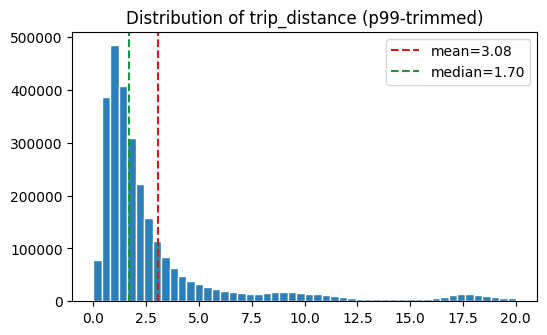

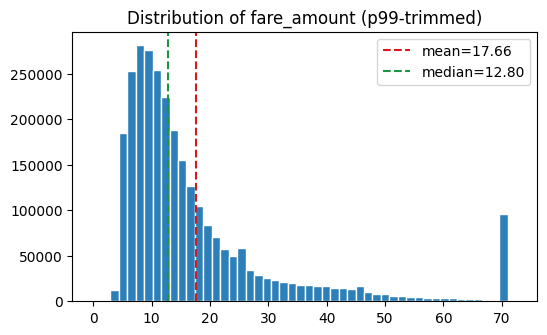

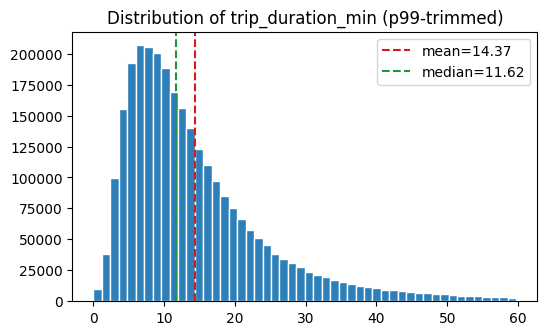

In [7]:
for col in ["trip_distance", "fare_amount", "trip_duration_min"]:
    s = analytic[col]
    s = s[s <= s.quantile(0.99)]
    plt.figure(figsize=(6, 3.5))
    plt.hist(s, bins=50, color="#2c7fb8", edgecolor="white")
    plt.axvline(s.mean(), color="#d7191c", linestyle="--", label=f"mean={s.mean():.2f}")
    plt.axvline(s.median(), color="#1a9641", linestyle="--", label=f"median={s.median():.2f}")
    plt.title(f"Distribution of {col} (p99-trimmed)")
    plt.legend()
    plt.show()

## 6. Multivariate exploratory analysis

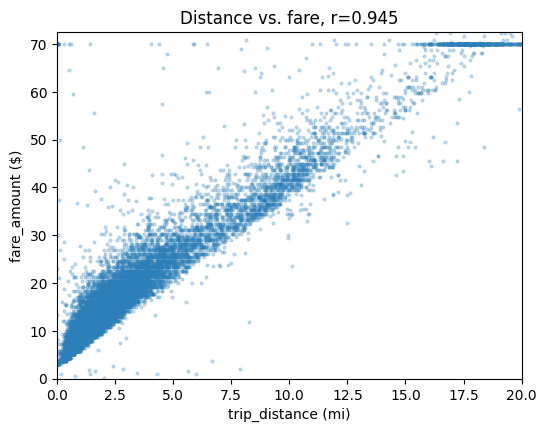

In [8]:
sample = analytic.sample(min(20000, len(analytic)), random_state=A.SEED)
r = analytic["trip_distance"].corr(analytic["fare_amount"])
plt.figure(figsize=(6, 4.5))
plt.scatter(sample["trip_distance"], sample["fare_amount"], s=4, alpha=0.25, color="#2c7fb8")
plt.xlim(0, analytic["trip_distance"].quantile(0.99))
plt.ylim(0, analytic["fare_amount"].quantile(0.99))
plt.xlabel("trip_distance (mi)"); plt.ylabel("fare_amount ($)")
plt.title(f"Distance vs. fare, r={r:.3f}")
plt.show()

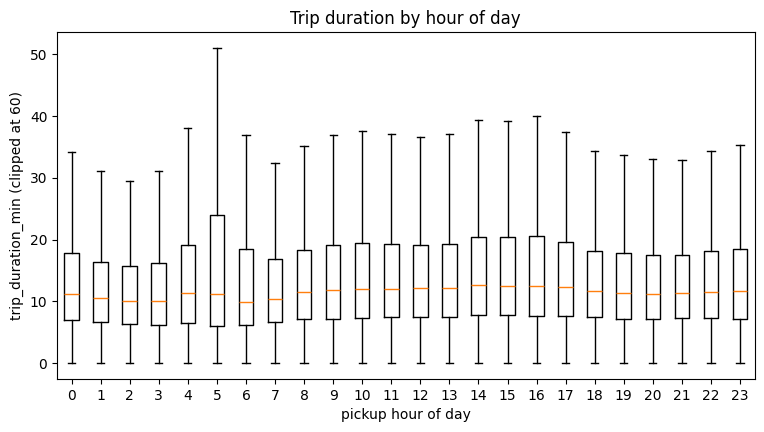

In [9]:
data = [analytic.loc[analytic["pickup_hour"] == h, "trip_duration_min"].clip(upper=60) for h in range(24)]
plt.figure(figsize=(9, 4.5))
plt.boxplot(data, positions=range(24), showfliers=False)
plt.xlabel("pickup hour of day"); plt.ylabel("trip_duration_min (clipped at 60)")
plt.title("Trip duration by hour of day")
plt.show()

## 7. Path A — Trip-time audit (hourly / weekday-weekend demand)

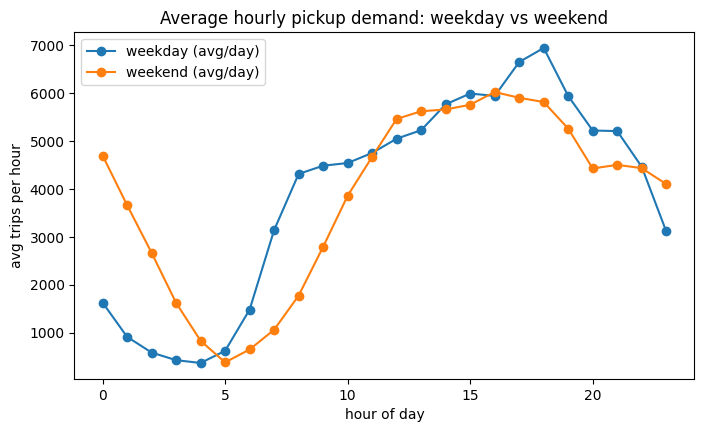

In [10]:
weekday = analytic[~analytic["is_weekend"]].groupby("pickup_hour").size() / analytic.loc[~analytic["is_weekend"], "pickup_date"].nunique()
weekend = analytic[analytic["is_weekend"]].groupby("pickup_hour").size() / analytic.loc[analytic["is_weekend"], "pickup_date"].nunique()
plt.figure(figsize=(8, 4.5))
plt.plot(weekday.index, weekday.values, marker="o", label="weekday (avg/day)")
plt.plot(weekend.index, weekend.values, marker="o", label="weekend (avg/day)")
plt.xlabel("hour of day"); plt.ylabel("avg trips per hour")
plt.title("Average hourly pickup demand: weekday vs weekend")
plt.legend(); plt.show()

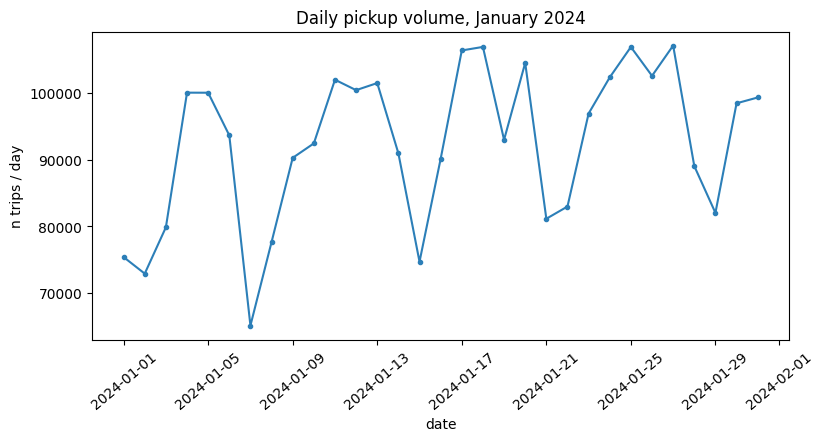

pickup_date
2024-01-07    65131
2024-01-02    72919
2024-01-15    74705
dtype: int64

In [11]:
daily = analytic.groupby("pickup_date").size()
plt.figure(figsize=(9, 4))
plt.plot(pd.to_datetime(daily.index), daily.values, marker="o", markersize=3, color="#2c7fb8")
plt.xlabel("date"); plt.ylabel("n trips / day")
plt.title("Daily pickup volume, January 2024")
plt.xticks(rotation=40)
plt.show()
daily.sort_values().head(3)

The sharpest dip (Jan 8, 2024) coincides with a winter storm that affected
the NYC area in early January 2024 — noted as a plausible explanation, not a
confirmed causal claim (see leakage/ethics discussion in the PDF report).

## 8. Path A — Variable consistency (speed, fare-per-mile)

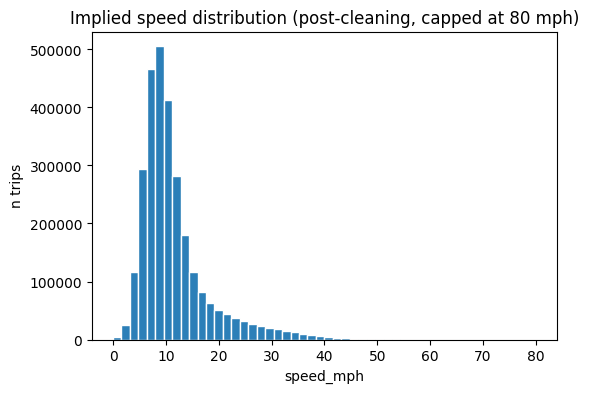

count    2.866703e+06
mean     1.146996e+01
std      1.403176e+02
min      1.560062e-04
25%      5.746753e+00
50%      7.181818e+00
75%      9.017341e+00
max      5.000000e+04
Name: fare_per_mile, dtype: float64

In [12]:
plt.figure(figsize=(6, 4))
plt.hist(analytic["speed_mph"], bins=50, color="#2c7fb8", edgecolor="white")
plt.xlabel("speed_mph"); plt.ylabel("n trips")
plt.title("Implied speed distribution (post-cleaning, capped at 80 mph)")
plt.show()
analytic["fare_per_mile"].describe()

## 9. Path A — Initial spatial snapshot

In [13]:
borough_counts, zone_counts = A.spatial_summary(analytic, zones)
borough_counts

,borough,n_trips,pct
0,Manhattan,2571245,89.69
1,Queens,257249,8.97
2,Brooklyn,22209,0.77
3,Unknown,9575,0.33
4,Bronx,5741,0.20
5,Unmatched (PULocationID not in zone lookup),599,0.02
6,Staten Island,43,0.00
7,EWR,42,0.00


In [14]:
zone_counts

,zone,n_trips,pct
0,Upper East Side South,140044,4.89
1,Midtown Center,140044,4.89
2,JFK Airport,138161,4.82
3,Upper East Side North,133875,4.67
4,Midtown East,104277,3.64
5,Times Sq/Theatre District,102853,3.59
6,Penn Station/Madison Sq West,102077,3.56
7,Lincoln Square East,101690,3.55
8,LaGuardia Airport,87625,3.06
9,Upper West Side South,86412,3.01


## 10. Path A — Anomaly candidates

In [15]:
anomalies = A.anomaly_candidates(A.derive_fields(raw))
anomalies

,anomaly_type,n_flagged,pct_of_raw
0,implausible_speed_gt_80mph,1107,0.0373
1,idle_meter_long_duration_zero_fare_move,9749,0.3288
2,very_high_fare_per_mile,2905,0.0980
3,zero_passenger_count,31465,1.0613


## 11. Summary

See `reports/phase1.pdf` for the full written report: problem framing, the
three candidate questions and the selected main question, data provenance,
leakage risks, baseline definition, and the preliminary train/validation/test
split plan. This notebook is the reproducible evidence behind every number
and figure in that report.